# ACM ATLAS — Tabular Classification Baselines
**Goal:** Predict footprint-defined data center size (`Small`, `Medium`, `Large`) from IM3 and EIA features.

This notebook is an **executable, documented research baseline**, separate from `atlas_pipeline.ipynb`. It does **not** modify the source CSV. Run top to bottom. Review the feature audit before training.

**Experiments:** IM3-only, EIA-only, IM3+EIA × Logistic Regression and Random Forest, plus DummyClassifier.

**Leakage policy:** `size_class` is computed from `sqft`, so `sqft` and the target must never be predictors. IDs, raw location, state/county identifiers, names and `ba_code` are excluded from the initial models. `type` is provisional and should be verified against the label-construction process.

**Caution:** These are size *proxies based on square footage*, not independently validated compute capacity or hyperscale labels.

## 1 — Setup and configuration
Install packages in your WSL environment if needed: `pip install pandas numpy scikit-learn matplotlib joblib nbformat`.

In [8]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    average_precision_score
)
from sklearn.preprocessing import label_binarize
import joblib

SEED = 42
DATA_PATH = Path("im3_atlas_combined.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/processed/im3_atlas_combined.csv")
OUTPUT_DIR = Path("outputs/tabular_baselines")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ["Small", "Medium", "Large"]
print("scikit-learn:", sklearn.__version__, "| CSV:", DATA_PATH.resolve())

scikit-learn: 1.9.1 | CSV: /mnt/data/processed/im3_atlas_combined.csv


## 2 — Load and audit
Verify shape, uniqueness, target distribution, missingness and type values before training.

In [10]:
DATA_PATH = Path("data/processed/im3_atlas_combined.csv")
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH.resolve()}"
print("Using dataset:", DATA_PATH.resolve())
df = pd.read_csv(DATA_PATH)
assert df.shape[0] > 0 and "size_class" in df and "id" in df
assert df["id"].notna().all() and df["id"].is_unique, "Facility IDs must be unique/nonmissing"
assert df["size_class"].notna().all()
assert set(df["size_class"].unique()) == {0, 1, 2}, "Expected labels 0/1/2"
print("Shape:", df.shape)
print("Class counts:")
display(df["size_class"].value_counts().sort_index().rename(index={0:"Small",1:"Medium",2:"Large"}).to_frame("n"))
print("Facility type values:")
display(df["type"].value_counts(dropna=False).to_frame("n"))
print("Missing columns (%), nonzero only:")
missing = df.isna().mean().mul(100).sort_values(ascending=False)
display(missing[missing > 0].round(2).to_frame("missing_pct"))
print("All columns:")
print(df.columns.tolist())

Using dataset: /mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/ATLAS/data/processed/im3_atlas_combined.csv
Shape: (1147, 49)
Class counts:


,n
size_class,
Small,111
Medium,330
Large,706


Facility type values:


,n
type,
building,1039
campus,108


Missing columns (%), nonzero only:


,missing_pct
ref,72.71
operator,35.83
name,18.31


All columns:
['id', 'state', 'state_abb', 'state_id', 'county', 'county_id', 'operator', 'ref', 'name', 'sqft', 'lon', 'lat', 'type', 'county_fips', 'size_class', 'nearest_plant_km', 'plants_50km', 'capacity_50km_mw', 'renewable_50km_mw', 'renewable_share_50km', 'nearest_big_plant_km', 'ba_code', 'ba_peak_mw', 'ba_avg_mw', 'ba_peak_to_avg', 'ba_demand_coverage', 'ba_share_coal', 'ba_share_gas', 'ba_share_nuclear', 'ba_share_hydro', 'ba_share_solar', 'ba_share_wind', 'ba_share_fossil', 'ba_share_renewable', 'ba_share_clean', 'ba_total_gen_mwh', 'retail_period', 'comm_elec_price_cents_kwh', 'comm_elec_sales_gwh', 'st_share_coal', 'st_share_gas', 'st_share_nuclear', 'st_share_hydro', 'st_share_solar', 'st_share_wind', 'st_share_fossil', 'st_share_renewable', 'st_share_clean', 'st_total_gen_mwh']


## 3 — Verify footprint label definition
This is an integrity check, **not** a step for deriving labels or creating predictors.

In [11]:
assert "sqft" in df.columns
print(df.groupby("size_class")["sqft"].agg(["count", "min", "median", "max"]))
# Confirm the known threshold rule; if violated, stop and review source preprocessing.
expected = np.select(
    [df["sqft"] < 20_000, df["sqft"] < 100_000],
    [0, 1], default=2
)
valid_sqft = df["sqft"].notna()
mismatch = (df.loc[valid_sqft, "size_class"].to_numpy() != expected[valid_sqft.to_numpy()]).sum()
print("Label/footprint mismatches:", mismatch)
assert mismatch == 0, "Check size_class thresholds in atlas_pipeline.ipynb" 

            count       min    median         max
size_class                                       
0             111     204.0   12565.0     19807.0
1             330   20213.0   55168.0     99760.0
2             706  100537.0  210782.0  26597517.0
Label/footprint mismatches: 0


## 4 — Explicit feature groups

**IM3:** `type` only in the initial leakage-conservative setup.

**EIA:** numeric plant proximity, generating capacity, balancing authority aggregates, retail electricity and state-level generation features.

Exclude all geography/IDs from the initial baseline. The notebook intentionally does not use `ba_code` or `retail_period` (potential categorical geographic/time proxies). No EIA field is allowed to be a target or square-footage transformation.

**Research checkpoint:** confirm with the team that `type` was not defined from footprint thresholds. If it was, remove it and treat the IM3-only experiment as unavailable rather than fabricating features.

In [12]:
IM3_FEATURES = ["type"]
EIA_FEATURES = [
    "nearest_plant_km", "plants_50km", "capacity_50km_mw",
    "renewable_50km_mw", "renewable_share_50km", "nearest_big_plant_km",
    "ba_peak_mw", "ba_avg_mw", "ba_peak_to_avg", "ba_demand_coverage",
    "ba_share_coal", "ba_share_gas", "ba_share_nuclear", "ba_share_hydro",
    "ba_share_solar", "ba_share_wind", "ba_share_fossil",
    "ba_share_renewable", "ba_share_clean", "ba_total_gen_mwh",
    "comm_elec_price_cents_kwh", "comm_elec_sales_gwh",
    "st_share_coal", "st_share_gas", "st_share_nuclear", "st_share_hydro",
    "st_share_solar", "st_share_wind", "st_share_fossil",
    "st_share_renewable", "st_share_clean", "st_total_gen_mwh"
]
FEATURE_GROUPS = {
    "IM3": IM3_FEATURES,
    "EIA": EIA_FEATURES,
    "IM3_EIA": IM3_FEATURES + EIA_FEATURES,
}
LEAKAGE_FIELDS = {"id", "sqft", "size_class", "lat", "lon", "name", "operator", "ref",
                  "state", "state_abb", "state_id", "county", "county_id", "county_fips",
                  "ba_code", "retail_period"}
for group, features in FEATURE_GROUPS.items():
    assert len(features) == len(set(features))
    assert not LEAKAGE_FIELDS.intersection(features)
    assert set(features).issubset(df.columns), f"Missing {set(features)-set(df.columns)}"
    print(f"{group}: {len(features)} features")
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in EIA_FEATURES)
display(pd.DataFrame({"group": ["IM3", "EIA", "IM3+EIA"],
                      "features": [len(v) for v in FEATURE_GROUPS.values()]}))

IM3: 1 features
EIA: 32 features
IM3_EIA: 33 features


,group,features
0,IM3,1
1,EIA,32
2,IM3+EIA,33


## 5 — Fixed stratified splits (70/15/15)

Split **before fitting** any imputer, scaler or encoder. All models use exactly the same facility IDs. The test set is held out from model selection. We save split IDs for reproducibility.

**Spatial generalization** is a separate experiment to run later; random stratification alone cannot measure performance on unseen regions.

In [13]:
y = df["size_class"].astype(int)
all_idx = np.arange(len(df))
train_idx, holdout_idx = train_test_split(
    all_idx, test_size=0.30, random_state=SEED, stratify=y
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, random_state=SEED,
    stratify=y.iloc[holdout_idx]
)
assert not (set(train_idx)&set(val_idx) or set(train_idx)&set(test_idx) or set(val_idx)&set(test_idx))
assert len(set(train_idx)|set(val_idx)|set(test_idx)) == len(df)
split_manifest = pd.DataFrame({
    "id": df["id"],
    "split": np.select(
        [np.isin(all_idx, train_idx), np.isin(all_idx, val_idx)],
        ["train", "val"], default="test"
    ),
    "size_class": y,
})
split_manifest.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
display(pd.crosstab(split_manifest["split"], split_manifest["size_class"]))
print("Split manifest:", OUTPUT_DIR / "split_manifest.csv")

size_class,0,1,2
split,,,
test,17,50,106
train,77,231,494
val,17,49,106


Split manifest: outputs/tabular_baselines/split_manifest.csv


## 6 — Leakage-safe preprocessing and models
All learned transformations are inside the estimator pipeline, so fitting on train data cannot learn validation/test statistics.

In [14]:
def make_preprocessor(features, scale_numeric):
    numeric = [c for c in features if c in EIA_FEATURES]
    categorical = [c for c in features if c in IM3_FEATURES]
    transformers = []
    if numeric:
        steps = [("imputer", SimpleImputer(strategy="median"))]
        if scale_numeric:
            steps.append(("scaler", StandardScaler()))
        transformers.append(("num", Pipeline(steps), numeric))
    if categorical:
        transformers.append(("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical))
    return ColumnTransformer(transformers, remainder="drop")

def make_model(kind, features):
    if kind == "LogisticRegression":
        classifier = LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)
        scale = True
    elif kind == "RandomForest":
        classifier = RandomForestClassifier(
            n_estimators=300, min_samples_leaf=3,
            class_weight="balanced_subsample", random_state=SEED, n_jobs=-1
        )
        scale = False
    elif kind == "Dummy":
        classifier = DummyClassifier(strategy="prior")
        scale = False
    else:
        raise ValueError(kind)
    return Pipeline([("preprocess", make_preprocessor(features, scale)),
                     ("classifier", classifier)])

## 7 — Metrics

**Primary:** macro-F1. Also record balanced accuracy, overall accuracy, per-class precision/recall/F1, and one-vs-rest average precision (PR-AUC summary) using class probabilities.

We report train and validation metrics to diagnose overfitting. No test metrics are used for choosing a model.

In [15]:
LABELS = np.array([0, 1, 2])

def evaluate(model, X, y_true):
    pred = model.predict(X)
    proba = model.predict_proba(X)
    # Ensure probability columns match class order.
    order = list(model.classes_)
    proba = proba[:, [order.index(c) for c in LABELS]]
    y_binary = label_binarize(y_true, classes=LABELS)
    p, r, f1, support = precision_recall_fscore_support(
        y_true, pred, labels=LABELS, zero_division=0
    )
    ap = [average_precision_score(y_binary[:, i], proba[:, i])
          if y_binary[:, i].sum() > 0 else np.nan for i in range(3)]
    summary = {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "macro_pr_auc": float(np.nanmean(ap)),
    }
    for i, name in enumerate(CLASS_NAMES):
        summary.update({f"{name.lower()}_precision": p[i],
                        f"{name.lower()}_recall": r[i],
                        f"{name.lower()}_f1": f1[i],
                        f"{name.lower()}_support": int(support[i]),
                        f"{name.lower()}_pr_auc": ap[i]})
    return summary, pred

## 8 — Run baseline experiments

Train **six configurations** plus a DummyClassifier reference. This notebook uses **fixed, conservative starter hyperparameters**, not a hyperparameter search. Later tuning must use training/validation only.

To keep results reproducible, write metrics and models into one output directory rather than making new CSV datasets.

In [16]:
results = []
trained = {}
experiments = [("Dummy", "EIA")] + [
    (kind, group)
    for group in FEATURE_GROUPS
    for kind in ("LogisticRegression", "RandomForest")
]
for kind, group in experiments:
    features = FEATURE_GROUPS[group]
    X_train = df.iloc[train_idx][features]
    X_val = df.iloc[val_idx][features]
    model = make_model(kind, features)
    model.fit(X_train, y.iloc[train_idx])
    train_metrics, _ = evaluate(model, X_train, y.iloc[train_idx])
    val_metrics, _ = evaluate(model, X_val, y.iloc[val_idx])
    key = f"{group}__{kind}"
    trained[key] = model
    joblib.dump(model, OUTPUT_DIR / f"{key}.joblib")
    results.append({
        "experiment": key, "group": group, "model": kind,
        "n_features": len(features),
        "train_macro_f1": train_metrics["macro_f1"],
        **{f"val_{k}": v for k, v in val_metrics.items()}
    })
    print(f"{key:32s} train macro-F1={train_metrics['macro_f1']:.3f} "
          f"val macro-F1={val_metrics['macro_f1']:.3f}")

results_df = pd.DataFrame(results).sort_values("val_macro_f1", ascending=False)
results_df.to_csv(OUTPUT_DIR / "validation_metrics.csv", index=False)
display(results_df[["experiment", "train_macro_f1", "val_macro_f1",
                    "val_balanced_accuracy", "val_macro_pr_auc"]])

EIA__Dummy                       train macro-F1=0.254 val macro-F1=0.254
IM3__LogisticRegression          train macro-F1=0.251 val macro-F1=0.236
IM3__RandomForest                train macro-F1=0.251 val macro-F1=0.236
EIA__LogisticRegression          train macro-F1=0.494 val macro-F1=0.389
EIA__RandomForest                train macro-F1=0.825 val macro-F1=0.533
IM3_EIA__LogisticRegression      train macro-F1=0.501 val macro-F1=0.412
IM3_EIA__RandomForest            train macro-F1=0.839 val macro-F1=0.543


,experiment,train_macro_f1,val_macro_f1,val_balanced_accuracy,val_macro_pr_auc
6,IM3_EIA__RandomForest,0.838849,0.542758,0.548204,0.559835
4,EIA__RandomForest,0.825420,0.533374,0.538257,0.551981
5,IM3_EIA__LogisticRegression,0.501075,0.411626,0.458780,0.469542
3,EIA__LogisticRegression,0.494317,0.388650,0.435740,0.426602
0,EIA__Dummy,0.254115,0.254197,0.333333,0.333333
2,IM3__RandomForest,0.251488,0.235711,0.377358,0.357329
1,IM3__LogisticRegression,0.251488,0.235711,0.377358,0.357329


## 9 — Compare validation results
The chart below is for model selection only. Test results remain untouched.

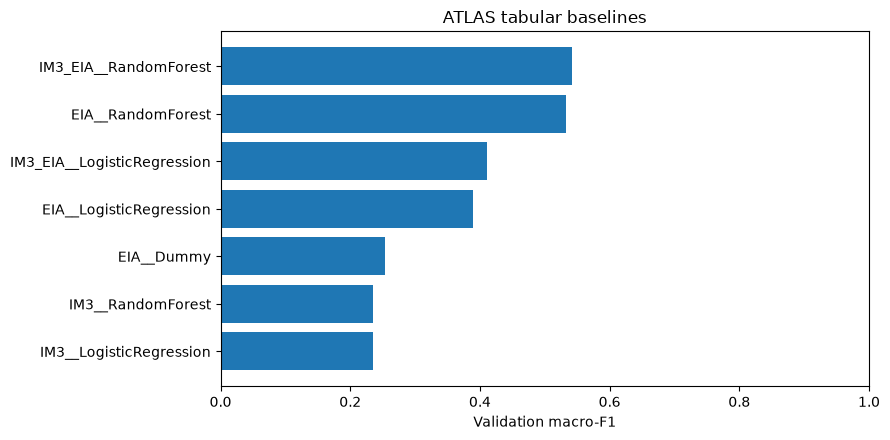

Best non-dummy validation model: IM3_EIA__RandomForest


In [17]:
plot_df = results_df.sort_values("val_macro_f1")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_df["experiment"], plot_df["val_macro_f1"])
ax.set(xlabel="Validation macro-F1", title="ATLAS tabular baselines")
ax.set_xlim(0, 1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_macro_f1.png", dpi=160)
plt.show()
best = results_df.loc[results_df["model"] != "Dummy"].iloc[0]
print("Best non-dummy validation model:", best["experiment"])

## 10 — Final held-out test (run once after selection)

**Stop here until the feature audit and model choice are approved.** Set `RUN_FINAL_TEST = True` only when ready to report final results. This evaluates the already-fitted validation-selected model on test data; it does not refit on train+validation. A future production workflow may refit after evaluation, with careful provenance.

In [18]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    key = best["experiment"]
    group = best["group"]
    model = trained[key]
    test_metrics, test_pred = evaluate(
        model, df.iloc[test_idx][FEATURE_GROUPS[group]], y.iloc[test_idx]
    )
    print("Selected:", key)
    print(json.dumps(test_metrics, indent=2))
    print(classification_report(y.iloc[test_idx], test_pred,
                                labels=LABELS, target_names=CLASS_NAMES, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y.iloc[test_idx], test_pred, labels=LABELS, display_labels=CLASS_NAMES
    )
    plt.title(f"Test confusion matrix: {key}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=160)
    plt.show()
    with open(OUTPUT_DIR / "final_test_metrics.json", "w") as f:
        json.dump({"experiment": key, "metrics": test_metrics}, f, indent=2)
else:
    print("Final test intentionally locked. Review validation findings first.")

Final test intentionally locked. Review validation findings first.


## Model Diagnostics — Per-Class Performance

Compare EIA-only and IM3+EIA Random Forest models
using classification reports and confusion matrices
on the validation set.

The test set remains untouched.


EIA Random Forest
              precision    recall  f1-score   support

       Small      0.286     0.235     0.258        17
      Medium      0.533     0.653     0.587        49
       Large      0.786     0.726     0.755       106

    accuracy                          0.657       172
   macro avg      0.535     0.538     0.533       172
weighted avg      0.664     0.657     0.658       172


IM3 + EIA Random Forest
              precision    recall  f1-score   support

       Small      0.286     0.235     0.258        17
      Medium      0.550     0.673     0.606        49
       Large      0.796     0.736     0.765       106

    accuracy                          0.669       172
   macro avg      0.544     0.548     0.543       172
weighted avg      0.675     0.669     0.669       172



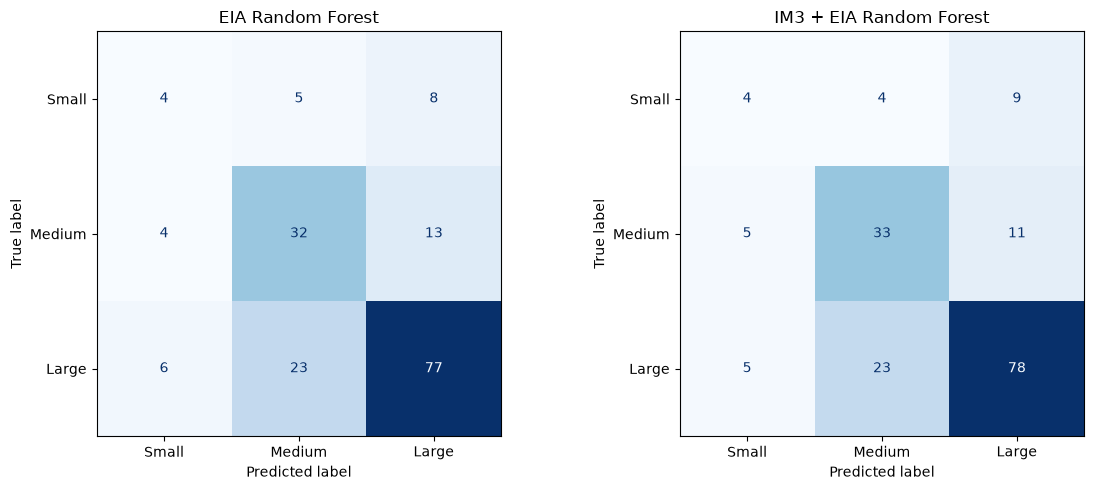

In [19]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

models_to_compare = {
    "EIA Random Forest": "EIA__RandomForest",
    "IM3 + EIA Random Forest": "IM3_EIA__RandomForest"
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, key) in zip(axes, models_to_compare.items()):

    model = trained[key]

    group = "EIA" if key.startswith("EIA__") else "IM3_EIA"

    X_val = df.iloc[val_idx][FEATURE_GROUPS[group]]
    y_val = y.iloc[val_idx]

    predictions = model.predict(X_val)

    print(f"\n{'='*55}")
    print(name)
    print(f"{'='*55}")

    print(
        classification_report(
            y_val,
            predictions,
            labels=[0, 1, 2],
            target_names=["Small", "Medium", "Large"],
            digits=3,
            zero_division=0
        )
    )

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        labels=[0, 1, 2],
        display_labels=["Small", "Medium", "Large"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

## permutation feature importance

,feature,importance_mean,importance_std
2,plants_50km,0.050504,0.011403
6,nearest_big_plant_km,0.038214,0.012771
3,capacity_50km_mw,0.035495,0.013536
4,renewable_50km_mw,0.029310,0.014747
17,ba_share_fossil,0.028228,0.010822
0,type,0.025085,0.007897
18,ba_share_renewable,0.017843,0.015667
21,comm_elec_price_cents_kwh,0.015918,0.007695
5,renewable_share_50km,0.013558,0.008639
16,ba_share_wind,0.010881,0.011109


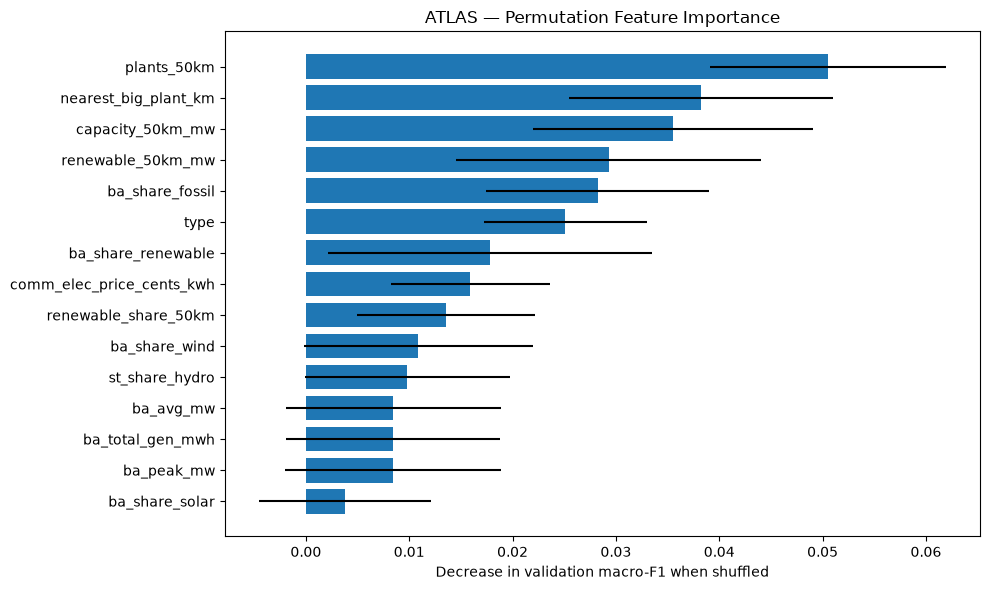

In [20]:
from sklearn.inspection import permutation_importance

model = trained["IM3_EIA__RandomForest"]

X_val = df.iloc[val_idx][FEATURE_GROUPS["IM3_EIA"]]
y_val = y.iloc[val_idx]

result = permutation_importance(
    model,
    X_val,
    y_val,
    scoring="f1_macro",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(15))

# Plot top 15 features
top = importance_df.head(15).sort_values("importance_mean")

plt.figure(figsize=(10, 6))

plt.barh(
    top["feature"],
    top["importance_mean"],
    xerr=top["importance_std"]
)

plt.xlabel("Decrease in validation macro-F1 when shuffled")
plt.title("ATLAS — Permutation Feature Importance")
plt.tight_layout()
plt.show()

## random forest regularization 

In [21]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

X_train = df.iloc[train_idx][FEATURE_GROUPS["IM3_EIA"]]
y_train = y.iloc[train_idx]

pipeline = make_model(
    "RandomForest",
    FEATURE_GROUPS["IM3_EIA"]
)

param_grid = {
    "classifier__max_depth": [5, 10, 15],
    "classifier__min_samples_leaf": [3, 5, 10],
    "classifier__max_features": ["sqrt", 0.5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

grid.fit(X_train, y_train)

print("Best parameters:")
print(grid.best_params_)

print("\nBest cross-validation macro-F1:")
print(round(grid.best_score_, 4))

cv_results = pd.DataFrame(grid.cv_results_)

display(
    cv_results[
        [
            "param_classifier__max_depth",
            "param_classifier__min_samples_leaf",
            "param_classifier__max_features",
            "mean_train_score",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    ).head(10)
)

,param_classifier__max_depth,param_classifier__min_samples_leaf,param_classifier__max_features,mean_train_score,mean_test_score,std_test_score
15,15,3,0.5,0.887239,0.507118,0.026222
6,10,3,sqrt,0.809347,0.502723,0.039359
9,10,3,0.5,0.864291,0.499058,0.035278
17,15,10,0.5,0.692698,0.496324,0.029831
11,10,10,0.5,0.692318,0.495039,0.030200
13,15,5,sqrt,0.741674,0.489271,0.018016
10,10,5,0.5,0.799735,0.487745,0.030847
16,15,5,0.5,0.809692,0.487298,0.028455
4,5,5,0.5,0.680621,0.485903,0.023750
7,10,5,sqrt,0.735598,0.485376,0.021598


## tuned value evalutation

Tuned Random Forest Validation Results
Macro-F1: 0.5547
Balanced accuracy: 0.5545

Classification Report:
              precision    recall  f1-score   support

       Small      0.364     0.235     0.286        17
      Medium      0.550     0.673     0.606        49
       Large      0.792     0.755     0.773       106

    accuracy                          0.680       172
   macro avg      0.569     0.554     0.555       172
weighted avg      0.681     0.680     0.677       172



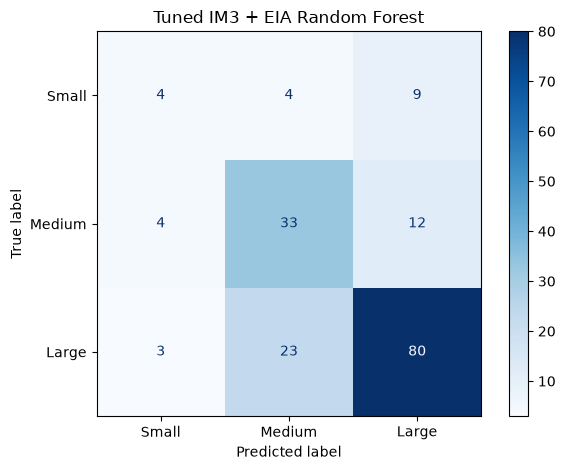

In [22]:
# Retrieve the best model
tuned_model = grid.best_estimator_

# Use the same validation data as our original baseline
X_val = df.iloc[val_idx][FEATURE_GROUPS["IM3_EIA"]]
y_val = y.iloc[val_idx]

# Evaluate
tuned_metrics, tuned_predictions = evaluate(
    tuned_model,
    X_val,
    y_val
)

print("Tuned Random Forest Validation Results")
print("=" * 45)

print("Macro-F1:", round(tuned_metrics["macro_f1"], 4))
print("Balanced accuracy:", round(tuned_metrics["balanced_accuracy"], 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        tuned_predictions,
        labels=[0, 1, 2],
        target_names=["Small", "Medium", "Large"],
        digits=3,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    tuned_predictions,
    labels=[0, 1, 2],
    display_labels=["Small", "Medium", "Large"],
    cmap="Blues"
)

plt.title("Tuned IM3 + EIA Random Forest")
plt.tight_layout()
plt.show()

## Inspecting geographic coverage

In [23]:
# Geographic coverage and class distribution
state_distribution = pd.crosstab(
    df["state"],
    df["size_class"]
)

state_distribution.columns = [
    "Small",
    "Medium",
    "Large"
]

state_distribution["Total"] = state_distribution.sum(axis=1)

print("Number of states:", len(state_distribution))

display(
    state_distribution.sort_values(
        "Total",
        ascending=False
    ).head(20)
)

print("\nStates containing all three classes:")
print(
    (
        state_distribution[["Small", "Medium", "Large"]] > 0
    ).all(axis=1).sum()
)

Number of states: 42


,Small,Medium,Large,Total
state,,,,
Virginia,15,54,219,288
Oregon,14,13,64,91
Texas,4,28,57,89
California,9,53,21,83
Washington,16,19,46,81
Iowa,4,7,45,56
Ohio,4,9,42,55
New Jersey,4,19,22,45
Arizona,3,11,26,40



States containing all three classes:
21


## Spatial Generalization — State-Grouped Cross-Validation

Evaluate whether the tabular classifier generalizes to
data centers in states excluded from training.

All experiments run locally in WSL.
The original held-out test set remains untouched.

In [24]:
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd
import numpy as np

# Only use the original training partition
train_df = df.iloc[train_idx].copy()

X_spatial = train_df[FEATURE_GROUPS["IM3_EIA"]]
y_spatial = train_df["size_class"].astype(int)
groups = train_df["state"]

spatial_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

spatial_splits = list(
    spatial_cv.split(X_spatial, y_spatial, groups)
)

fold_summary = []

for fold, (tr_idx, va_idx) in enumerate(spatial_splits, start=1):

    train_states = set(groups.iloc[tr_idx])
    val_states = set(groups.iloc[va_idx])

    assert train_states.isdisjoint(val_states)

    fold_summary.append({
        "Fold": fold,
        "Train facilities": len(tr_idx),
        "Validation facilities": len(va_idx),
        "Validation states": len(val_states),
        "Small": int((y_spatial.iloc[va_idx] == 0).sum()),
        "Medium": int((y_spatial.iloc[va_idx] == 1).sum()),
        "Large": int((y_spatial.iloc[va_idx] == 2).sum())
    })

fold_df = pd.DataFrame(fold_summary)

display(fold_df)

,Fold,Train facilities,Validation facilities,Validation states,Small,Medium,Large
0,1,642,160,8,15,46,99
1,2,661,141,7,14,46,81
2,3,580,222,6,15,46,161
3,4,694,108,9,14,47,47
4,5,631,171,9,19,46,106


# spacial cv

In [25]:
from sklearn.base import clone
from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score

# Compare original and tuned Random Forests
spatial_models = {
    "Original RF": trained["IM3_EIA__RandomForest"],
    "Tuned RF": grid.best_estimator_
}

spatial_results = []

for model_name, base_model in spatial_models.items():

    for fold, (tr_idx, va_idx) in enumerate(spatial_splits, start=1):

        # Clone to ensure each fold starts with an unfitted model
        model = clone(base_model)

        X_tr = X_spatial.iloc[tr_idx]
        X_va = X_spatial.iloc[va_idx]

        y_tr = y_spatial.iloc[tr_idx]
        y_va = y_spatial.iloc[va_idx]

        model.fit(X_tr, y_tr)
        predictions = model.predict(X_va)

        spatial_results.append({
            "model": model_name,
            "fold": fold,
            "n_validation": len(va_idx),
            "macro_f1": f1_score(
                y_va, predictions,
                average="macro",
                labels=[0, 1, 2],
                zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_va, predictions
            ),
            "small_recall": recall_score(
                y_va, predictions,
                labels=[0, 1, 2],
                average=None,
                zero_division=0
            )[0]
        })

spatial_results_df = pd.DataFrame(spatial_results)

display(spatial_results_df)

,model,fold,n_validation,macro_f1,balanced_accuracy,small_recall
0,Original RF,1,160,0.382177,0.473898,0.600000
1,Original RF,2,141,0.327549,0.373169,0.142857
2,Original RF,3,222,0.230107,0.349896,0.000000
3,Original RF,4,108,0.332391,0.390071,0.000000
4,Original RF,5,171,0.328840,0.328454,0.052632
5,Tuned RF,1,160,0.380743,0.389562,0.133333
6,Tuned RF,2,141,0.310023,0.310623,0.071429
7,Tuned RF,3,222,0.260932,0.406832,0.000000
8,Tuned RF,4,108,0.382838,0.418440,0.000000
9,Tuned RF,5,171,0.271485,0.280191,0.052632


# summary 

In [26]:
spatial_summary = (
    spatial_results_df
    .groupby("model")
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_small_recall=("small_recall", "mean")
    )
    .round(4)
)

display(spatial_summary)

,mean_macro_f1,std_macro_f1,mean_balanced_accuracy,mean_small_recall
model,,,,
Original RF,0.3202,0.0553,0.3831,0.1591
Tuned RF,0.3212,0.0583,0.3611,0.0515


## Diagnostioc held out test 

In [27]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score

dummy_results = []

for fold, (tr_idx, va_idx) in enumerate(spatial_splits, start=1):

    dummy = DummyClassifier(strategy="most_frequent")

    dummy.fit(
        X_spatial.iloc[tr_idx],
        y_spatial.iloc[tr_idx]
    )

    predictions = dummy.predict(X_spatial.iloc[va_idx])

    dummy_results.append({
        "fold": fold,
        "macro_f1": f1_score(
            y_spatial.iloc[va_idx],
            predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_spatial.iloc[va_idx],
            predictions
        )
    })

dummy_spatial_df = pd.DataFrame(dummy_results)

display(dummy_spatial_df)

print(
    "\nMean spatial dummy macro-F1:",
    round(dummy_spatial_df["macro_f1"].mean(), 4)
)

,fold,macro_f1,balanced_accuracy
0,1,0.254826,0.333333
1,2,0.243243,0.333333
2,3,0.280244,0.333333
3,4,0.202151,0.333333
4,5,0.255114,0.333333



Mean spatial dummy macro-F1: 0.2471


## saving metadata

In [28]:
import json
import joblib

selected_model = grid.best_estimator_

model_path = OUTPUT_DIR / "selected_tabular_model.joblib"
metadata_path = OUTPUT_DIR / "selected_model_metadata.json"

joblib.dump(selected_model, model_path)

metadata = {
    "project": "ACM ATLAS",
    "objective": "Three-class footprint-based data center size classification",
    "selected_model": "IM3 + EIA Random Forest",
    "selection_metric": "validation_macro_f1",
    "validation_macro_f1": 0.5547,
    "cv_macro_f1": float(grid.best_score_),
    "hyperparameters": grid.best_params_,
    "features": FEATURE_GROUPS["IM3_EIA"],
    "random_state": 42,
    "test_evaluated": False
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Model saved:", model_path)
print("Metadata saved:", metadata_path)

Model saved: outputs/tabular_baselines/selected_tabular_model.joblib
Metadata saved: outputs/tabular_baselines/selected_model_metadata.json


## saved model evals

In [30]:
# Reconstruct the original held-out test partition
X_test = df.iloc[test_idx][FEATURE_GROUPS["IM3_EIA"]].copy()
y_test = df.iloc[test_idx]["size_class"].astype(int).copy()

print("Test samples:", len(X_test))
print("\nClass distribution:")
print(y_test.value_counts().sort_index())

print("\nFeatures:", X_test.shape[1])

Test samples: 173

Class distribution:
size_class
0     17
1     50
2    106
Name: count, dtype: int64

Features: 33


In [31]:
import joblib
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    accuracy_score
)

# Load the frozen model
final_model = joblib.load(
    OUTPUT_DIR / "selected_tabular_model.joblib"
)

# Use the original held-out test set
test_predictions = final_model.predict(X_test)

print("FINAL HELD-OUT TEST RESULTS")
print("-" * 40)

print("Macro-F1:", round(
    f1_score(y_test, test_predictions, average="macro"), 4
))

print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, test_predictions), 4
))

print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1, 2],
    target_names=["Small", "Medium", "Large"],
    zero_division=0
))

print("\nConfusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1, 2]),
    index=["Actual Small", "Actual Medium", "Actual Large"],
    columns=["Predicted Small", "Predicted Medium", "Predicted Large"]
))

FINAL HELD-OUT TEST RESULTS
----------------------------------------
Macro-F1: 0.5676
Balanced accuracy: 0.5622
Accuracy: 0.6879

Classification Report:
              precision    recall  f1-score   support

       Small       0.38      0.29      0.33        17
      Medium       0.56      0.60      0.58        50
       Large       0.79      0.79      0.79       106

    accuracy                           0.69       173
   macro avg       0.58      0.56      0.57       173
weighted avg       0.68      0.69      0.69       173


Confusion Matrix:


,Predicted Small,Predicted Medium,Predicted Large
Actual Small,5,5,7
Actual Medium,5,30,15
Actual Large,3,19,84


## svaing artifacts

In [32]:
import json
import sklearn
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, classification_report, confusion_matrix
)

final_metrics = {
    "model": "IM3_EIA_TunedRandomForest",
    "test_macro_f1": float(f1_score(
        y_test, test_predictions, average="macro"
    )),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, test_predictions)
    ),
    "test_accuracy": float(
        accuracy_score(y_test, test_predictions)
    ),
    "test_samples": int(len(y_test)),
    "sklearn_version": sklearn.__version__,
    "random_state": 42,
    "evaluation": "final_random_holdout"
}

with open(OUTPUT_DIR / "final_test_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=2)

pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1, 2]),
    index=["Small", "Medium", "Large"],
    columns=["Small", "Medium", "Large"]
).to_csv(OUTPUT_DIR / "final_test_confusion_matrix.csv")

pd.DataFrame(
    classification_report(
        y_test, test_predictions,
        labels=[0, 1, 2],
        target_names=["Small", "Medium", "Large"],
        output_dict=True,
        zero_division=0
    )
).T.to_csv(OUTPUT_DIR / "final_test_classification_report.csv")

print("Final evaluation artifacts saved.")

Final evaluation artifacts saved.


## 11 — Reproducibility and research notes

**Outputs** in `outputs/tabular_baselines/`:
- `split_manifest.csv` — facility IDs and shared split assignment
- `validation_metrics.csv` — comparable experiment scores
- `*.joblib` — fitted preprocessing+model pipelines
- `validation_macro_f1.png` — validation comparison
- Test metrics and confusion matrix only after explicit unlock

**Before the mentor meeting:**
1. Confirm how `type` is assigned and whether it is independent of footprint.
2. Examine whether EIA features have low variance, missingness, or extreme correlations.
3. Compare minority-class recall, not only macro-F1.
4. Evaluate spatial generalization with state-grouped splits as a follow-up experiment.
5. Port the validated logic into `train_tabular.py` for SageMaker.

**Do not commit generated model binaries or output folders unless the repository explicitly requires them.** Keep the combined CSV as the single authoritative input and avoid duplicating upstream notebooks.